# Four-terminal billiard

Run `python quantum_billiard.py` first. This notebook reads the saved results; it does not calculate the scattering matrix.

In [1]:
import json
from pathlib import Path

import kwant
import matplotlib.pyplot as plt
import numpy as np

from quantum_billiard import Parameters, make_system

results_path = Path('data') / 'conductance.npz'
with np.load(results_path, allow_pickle=False) as results:
    params = Parameters(**json.loads(results['parameters'].item()))
    lead_names = results['lead_names'].tolist()
    conductance = results['conductance'].copy()

print('Parameters:', params)
print('Lead order:', ', '.join(lead_names))
print('G (e²/h):\n', conductance)

Parameters: Parameters(length=40, width=30, lead_width=10, hopping=1.0, energy=0.8)
Lead order: left, right, bottom, top
G (e²/h):
 [[ 2.46126182 -1.3907498  -0.53525601 -0.53525601]
 [-1.3907498   2.46126182 -0.53525601 -0.53525601]
 [-0.53525601 -0.53525601  2.44128123 -1.37076921]
 [-0.53525601 -0.53525601 -1.37076921  2.44128123]]


## System and leads

The finite colored extensions show several unit cells of each semi-infinite lead. The system is reconstructed from the parameters saved with the matrix.

C:\Users\GersonFerreiraJunior\miniconda3\envs\gerson\Lib\site-packages\kwant\_plotter.py:77: RuntimeWarning: plotly is not available, if other engines are unavailable, only iterator-providing functions will work
  warnings.warn("plotly is not available, if other engines are unavailable,"


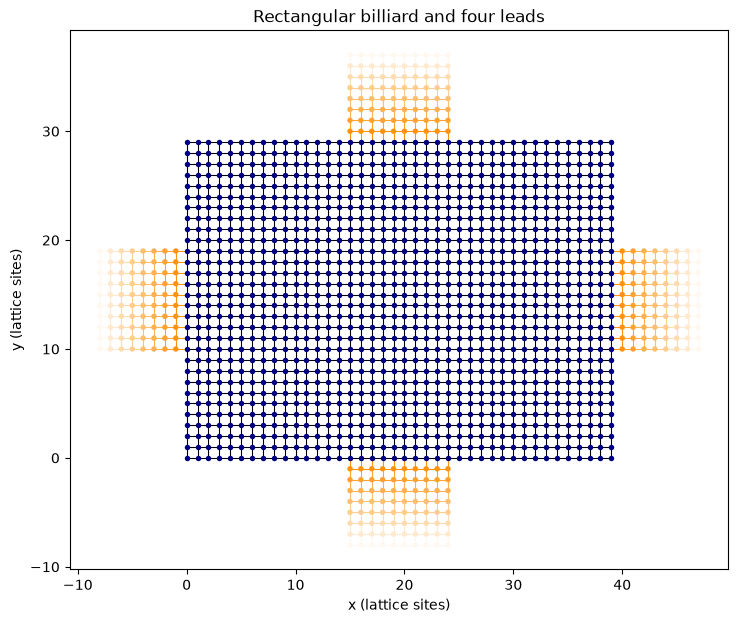

In [2]:
system = make_system(params)
fig = kwant.plot(system, num_lead_cells=8, site_size=0.25,
                 lead_site_size=0.25, site_color='navy',
                 lead_color='darkorange', show=False, fig_size=(9, 7))
ax = fig.axes[0]
ax.set_title('Rectangular billiard and four leads')
ax.set_xlabel('x (lattice sites)')
ax.set_ylabel('y (lattice sites)')
plt.show()

## Conductance matrix

Rows and columns follow the saved lead order. Off-diagonal entries are minus the transmission from column to row, in units of $e^2/h$.

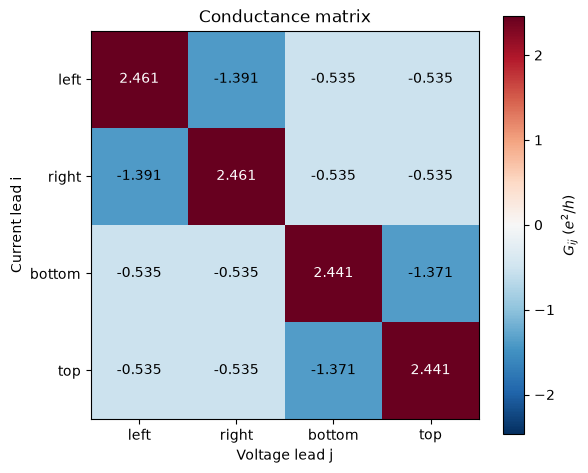

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
limit = np.max(np.abs(conductance))
image = ax.imshow(conductance, cmap='RdBu_r', vmin=-limit, vmax=limit)
ax.set_xticks(range(len(lead_names)), lead_names)
ax.set_yticks(range(len(lead_names)), lead_names)
ax.set_xlabel('Voltage lead j')
ax.set_ylabel('Current lead i')
ax.set_title('Conductance matrix')
for i in range(len(lead_names)):
    for j in range(len(lead_names)):
        ax.text(j, i, f'{conductance[i, j]:.3f}', ha='center', va='center',
                color='white' if limit and abs(conductance[i, j]) > 0.6 * limit else 'black')
fig.colorbar(image, ax=ax, label=r'$G_{ij}$ ($e^2/h$)')
fig.tight_layout()
plt.show()